# The neighborhood of `TreeCounterfactualExplainer`

`TreeCounterfactualExplainer` ([TreeCounterfactualExplainer.ipynb](TreeCounterfactualExplainer.ipynb)) trains its surrogate tree on a perturbed neighborhood of the instance, labeled by the model. This notebook shows how to:

1. **extract** the neighborhood of an explanation, or sample one without explaining;
2. **give your own neighborhood** to `explain`, for example a neighborhood NIFE built that you changed;
3. **give the explainer your own sampler**, used for every instance.

It uses the wine dataset bundled with scikit-learn. Requirements: `pip install "nife[notebooks]"`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier

from nife.counterfactual import TreeCounterfactualExplainer
from nife.counterfactual.tree import ADAPTIVE_NEIGHBORHOODS, fidelity_table

In [2]:
X, y = load_wine(return_X_y=True, as_frame=True)
model = RandomForestClassifier(random_state=0).fit(X, y)
explainer = TreeCounterfactualExplainer(model, X, random_state=0)

## 1. Extract the neighborhood

Every explanation keeps the neighborhood its tree was trained on in `explanation.neighborhood`. It has one row per point, with the features and the model's `prediction`. NIFE's sampling puts the instance itself in the first row.

In [3]:
explanation = explainer.explain(X.iloc[0])
explanation.neighborhood.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,prediction
0,14.230000,1.710000,2.430000,15.600000,127.000000,2.800000,3.060000,0.280000,2.290000,5.640000,1.040000,3.920000,1065.000000,0
1,13.643248,3.011395,2.450393,15.913627,116.779602,3.316755,1.408333,0.359804,2.368074,7.269660,1.053023,4.743484,1262.729858,0
2,14.177599,0.284434,2.268726,18.467550,132.331985,2.296237,4.360960,0.170748,2.285484,4.337612,1.129166,3.791412,1014.908081,0
3,13.556300,2.040248,2.682502,20.495863,136.594223,3.145280,2.949690,0.494619,1.995855,4.076350,1.093369,3.562187,1018.351929,0
4,15.204626,2.192388,2.886127,16.864994,135.537170,2.569379,3.666636,0.045977,2.881151,4.158250,1.155830,4.510204,1142.382324,0


With the adaptive neighborhood (the default), NIFE tries the neighborhoods of `ADAPTIVE_NEIGHBORHOODS`, from the narrowest, and keeps the first one whose tree has a counterfactual rule with evidence or a single-feature counterfactual. `explanation.neighborhood` is that last one, and `fidelity` says how it was sampled:

In [4]:
print(ADAPTIVE_NEIGHBORHOODS)  # (around the instance, scale of the standard deviation)
explanation.fidelity[["neighborhood", "sample_around_instance", "neighborhood_scale", "local_fidelity"]]

((True, 0.25), (True, 0.5), (True, 1.0), (False, 1.0))


neighborhood              sampled
sample_around_instance       True
neighborhood_scale            1.0
local_fidelity                1.0
dtype: object

How the model labels the neighborhood:

In [5]:
explanation.neighborhood["prediction"].value_counts()

prediction
0    752
1    135
2      3
Name: count, dtype: int64

The neighborhood on the two most relevant features. Each point is colored by the model's class, and the instance is the black cross:

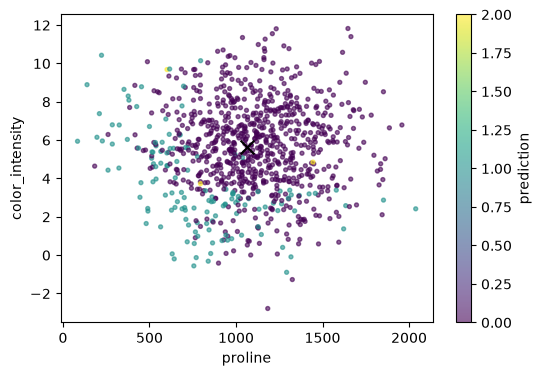

In [6]:
first, second = explanation.feature_importances.index[:2]
ax = explanation.neighborhood.plot.scatter(
    first, second, c="prediction", cmap="viridis", s=8, alpha=0.6, figsize=(6, 4)
)
ax.scatter(explanation.instance[first], explanation.instance[second], c="black", marker="x", s=100)
plt.show()

It is a DataFrame, so it can be saved and analyzed like any other: `explanation.neighborhood.to_csv("neighborhood.csv")`.

To get a neighborhood **without explaining**, use `sample_neighborhood`. It returns the features of the points; it is the model that labels them when explaining. By default it uses the explainer's settings (the neighborhood of `adaptive=False`). `around_instance`, `scale`, `num_samples` and `random_state` change them:

In [7]:
narrow = explainer.sample_neighborhood(X.iloc[0], around_instance=True, scale=0.25)
wide = explainer.sample_neighborhood(X.iloc[0], around_instance=False)
pd.DataFrame({"narrow": narrow.std(), "wide": wide.std(), "data": X.std()}).head()

,narrow,wide,data
alcohol,0.196773,0.788204,0.811827
malic_acid,0.277052,1.108407,1.117146
ash,0.068458,0.273838,0.274344
alcalinity_of_ash,0.796901,3.190060,3.339564
magnesium,3.611050,14.474623,14.282484


## 2. Give your own neighborhood to `explain`

`explain(x, neighborhood=...)` fits the tree on your neighborhood instead of sampling one. The adaptive neighborhood is then not used: a single tree is fitted on it. Passing back the neighborhood of an explanation gives the same explanation:

In [8]:
again = explainer.explain(X.iloc[0], neighborhood=explanation.neighborhood)
again.rules == explanation.rules, again.counterfactuals.equals(explanation.counterfactuals)

(True, True)

A common change: NIFE's normal sampling can produce points outside the range of the data, with values that no wine in the data has. Here we take the neighborhood that the adaptive search chose for this instance (around it, scale 1), keep only the points within the range of the data, and explain with them:

In [9]:
neighborhood = explainer.sample_neighborhood(X.iloc[0], around_instance=True, scale=1.0)
inside = ((neighborhood >= X.min()) & (neighborhood <= X.max())).all(axis=1)
print(f"{inside.mean():.0%} of the points are within the range of the data")

within_range = explainer.explain(X.iloc[0], neighborhood=neighborhood[inside])
within_range

27% of the points are within the range of the data


TreeCounterfactualExplanation (classification) of an instance predicted 0
  decision path: proline > 645.2
  relevant features: proline
  counterfactual rule: proline > 645.2 -> proline <= 645.2 (not confirmed: changing proline alone keeps the model's prediction)
  counterfactuals: 16, changing 2 features each (16 copied from evidence examples)
  closest: color_intensity 5.64 -> 3.25, proline 1065 -> 625; predicted 1 (distance 0.040; counterpart at distance 0.155)
  evidence: 83 examples of the data on the other side of the rule, the closest at distance 0.176
  fidelity: instance agreement True, local fidelity 1.00 (neighborhood: given)

The summary shows `neighborhood: given`. Check the fidelity with your own neighborhood too, because the rules only explain the prediction when the tree agrees with the model. If the tree has no decisions, the model gives every point the same outcome: widen the neighborhood.

Your neighborhood can also be a 2-D array with the features in the order of the data's columns. Other columns of a DataFrame, such as `prediction`, are ignored, because the model labels the points. Categorical features must use the data's codes, and immutable features are set to the instance's values.

## 3. Give the explainer your own sampler

For a neighborhood of your own for **every** instance, give the explainer a `sampler`. NIFE calls it as `sampler(instance, data, num_samples, random_state)`, with the instance as a Series, the reference data, the explainer's `num_samples` and a `numpy.random.RandomState`. It returns a DataFrame or a 2-D array.

This sampler draws points between the instance and random examples of the data, so the neighborhood follows the data instead of a normal distribution. It uses `random_state`, so the explanations stay reproducible:

In [10]:
def toward_the_data(instance, data, num_samples, random_state):
    """Points on the segments between the instance and random examples of the data."""
    examples = data.to_numpy()[random_state.randint(len(data), size=num_samples)]
    steps = random_state.uniform(0, 1, size=(num_samples, 1))
    return instance.to_numpy() + steps * (examples - instance.to_numpy())


custom = TreeCounterfactualExplainer(model, X, sampler=toward_the_data, random_state=0)
custom.explain(X.iloc[0])

TreeCounterfactualExplanation (classification) of an instance predicted 0
  decision path: alcohol > 13.04 and od280/od315_of_diluted_wines > 2.497 and proline > 650
  relevant features: alcohol, od280/od315_of_diluted_wines, flavanoids, proline
  counterfactual rule: proline > 650 -> proline <= 650 (not confirmed: changing proline alone keeps the model's prediction)
  counterfactuals: 11, changing 2 features each (11 copied from evidence examples)
  closest: malic_acid 1.71 -> 1.01, proline 1065 -> 502; predicted 1 (distance 0.042; counterpart at distance 0.134)
  evidence: 4 examples of the data on the other side of the rule, the closest at distance 0.176
  fidelity: instance agreement True, local fidelity 0.98 (neighborhood: from the sampler)

The sampler and NIFE's adaptive neighborhood on the same instances. Compare their fidelity and the quality of their counterfactuals:

In [11]:
instances = X.sample(20, random_state=0)
results = {}
for name, this in {"adaptive (default)": explainer, "toward the data": custom}.items():
    counterfactuals, explanations = this.explain_many(instances, return_explanations=True)
    fidelity = fidelity_table(explanations)
    results[name] = pd.concat([
        fidelity[["instance_agreement", "local_fidelity"]].astype(float).mean(),
        this.evaluate(instances, counterfactuals),
    ])
pd.DataFrame(results)

,adaptive (default),toward the data
instance_agreement,0.900000,1.000000
local_fidelity,0.880000,0.930000
coverage,0.900000,1.000000
count,11.833333,7.400000
validity,1.000000,1.000000
proximity,0.058231,0.065783
changed_features,2.111111,2.300000
redundancy,0.000000,0.000000
implausibility,0.057939,0.063866
ynn,0.225614,0.251186


A `neighborhood` given to `explain` or `explain_many` takes the place of the sampler. In `explain_many`, the same neighborhood is used for every instance, which suits a global sample:

In [12]:
global_sample = explainer.sample_neighborhood(X.iloc[0], around_instance=False)
counterfactuals = explainer.explain_many(instances, neighborhood=global_sample)
counterfactuals.groupby("instance").size().describe()

count    19.000000
mean      5.842105
std       4.349498
min       1.000000
25%       2.000000
50%       4.000000
75%       8.000000
max      15.000000
dtype: float64

## What a neighborhood of your own must be

These rules apply both to `neighborhood` and to the result of `sampler`:

- **Format.** A DataFrame with a column for each feature, or a 2-D array with the features in the order of the data's columns. Other columns of a DataFrame are ignored, such as the `prediction` of `explanation.neighborhood`.
- **Values.** Numeric and encoded like the data: categorical features use the same codes. They cannot be missing or infinite.
- **Labels.** The model labels the points, because NIFE explains the model. Labels you provide are not used.
- **Immutable features** are set to the instance's values, as in NIFE's sampling, so the tree does not split on them.
- **The instance.** NIFE's sampling puts the instance in the first row. Your neighborhood does not need to contain it.
- **Origin.** `explanation.fidelity["neighborhood"]` records where the neighborhood came from: `"sampled"` (NIFE), `"sampler"` or `"given"`.
- **Check the result.** Look at `fidelity` with your own neighborhood as well: the rules only explain the prediction when the tree agrees with the model. If the tree has no decisions, the model gives every point the same outcome, so widen the neighborhood.

The arguments of a sampler, `sampler(instance, data, num_samples, random_state)`:

| Argument | What it is |
|---|---|
| `instance` | the instance being explained, as a Series |
| `data` | the explainer's reference data (features only), as a DataFrame |
| `num_samples` | the explainer's `num_samples` (five times the size of `data` by default, at most 50,000) |
| `random_state` | a `numpy.random.RandomState` seeded from the explainer's `random_state`; use it so the explanations are reproducible |